<a href="https://colab.research.google.com/github/Tushar-3512/Data-Science-Practical-/blob/main/Practical_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
df = pd.read_csv('/content/drive/MyDrive/TeachingRatings.csv')

df.head()

,rownames,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,1,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,2,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,3,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,4,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,5,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5


Q1. Can you identify whether teachers Rating Data is a time serires or cross sectional?

In [6]:
print("Teaching Ratings data is cross-sectional data because it contains information about different teachers and their ratings, without tracking them over a sequence of time")
# Cross-sectional → many different teachers observed at one point/period
# Time series → same teacher/variable observed over time

Teaching Ratings data is cross-sectional data because it contains information about different teachers and their ratings, without tracking them over a sequence of time


Q2. Find the mean, median, minimum and maximum values for the students.

In [7]:
print("Mean:", df['students'].mean())
print("Median:", df['students'].median())
print("Minimum:", df['students'].min())
print("Maximum:", df['students'].max())

Mean: 36.62419006479482
Median: 23.0
Minimum: 5
Maximum: 380


Q3. Produce the descriptive statistics table.

In [14]:
df['students'].describe()
df.describe()

,rownames,age,beauty,eval,students,allstudents,prof
count,463.000000,463.000000,4.630000e+02,463.000000,463.000000,463.000000,463.000000
mean,232.000000,48.365011,6.263499e-08,3.998272,36.624190,55.177106,45.434125
std,133.800847,9.802742,7.886477e-01,0.554866,45.018481,75.072800,27.508902
min,1.000000,29.000000,-1.450494e+00,2.100000,5.000000,8.000000,1.000000
25%,116.500000,42.000000,-6.562689e-01,3.600000,15.000000,19.000000,20.000000
50%,232.000000,48.000000,-6.801430e-02,4.000000,23.000000,29.000000,44.000000
75%,347.500000,57.000000,5.456024e-01,4.400000,40.000000,60.000000,70.500000
max,463.000000,73.000000,1.970023e+00,5.000000,380.000000,581.000000,94.000000


Q4. Create a histogram of the beauty variable and breifly comment on the distribution of the data

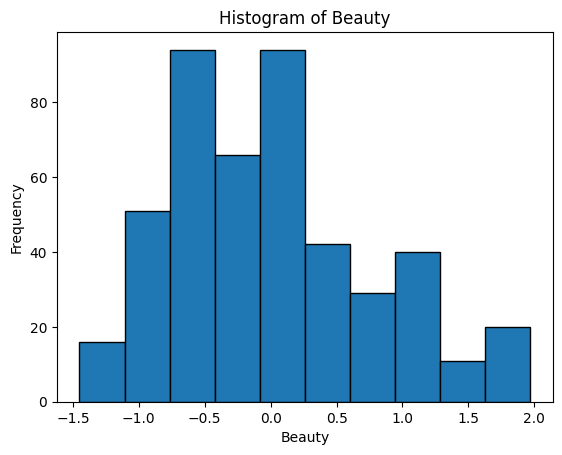

In [15]:
plt.hist(df['beauty'], bins=10, edgecolor='black')
plt.xlabel('Beauty')
plt.ylabel('Frequency')
plt.title('Histogram of Beauty')
plt.show()

Q5. Does average beauty score differ by gender? Produce the means and standard deviations for both male and female instructors.

In [16]:
df.groupby('gender')['beauty'].agg(['mean', 'std'])

,mean,std
gender,,
female,0.116109,0.81781
male,-0.084482,0.75713


Q6. Calculate the percentage of males and females that are tenured professors. Will you say that tenure status differ by gender?

In [25]:
tenure_by_gender = pd.crosstab(
    df['gender'],
    df['tenure'],
    normalize='index'
) * 100
print(tenure_by_gender)

tenure         no        yes
gender                      
female  25.641026  74.358974
male    19.402985  80.597015


Q6. Calculate the percentage of males and females that are tenured professors. Will you say that tenure status differ by gender?

In [18]:
df['tenure'].value_counts()

,count
tenure,
yes,361
no,102


In [24]:
percentage = pd.crosstab(
    df['gender'],
    df['tenure'],
    normalize='index'
) * 100
print(percentage)
#Will i say that tenure status differ by gender?

tenure         no        yes
gender                      
female  25.641026  74.358974
male    19.402985  80.597015


In [32]:
contingency_table = pd.crosstab(df['gender'], df['tenure'])
print(contingency_table)
from scipy.stats import chi2_contingency
chi2, p_value, dof, expected = chi2_contingency(contingency_table)
print("Chi-square statistic:", chi2)
print("p-value:", p_value)
print("Degrees of freedom:", dof)

tenure  no  yes
gender         
female  50  145
male    52  216
Chi-square statistic: 2.20678166999886
p-value: 0.1374050603563787
Degrees of freedom: 1


**Conclusion**-The percentage of tenured male professors is 80.60%, while for female professors it is 74.36%. Although there is a small difference, the p-value is 0.1374, which is greater than 0.05. Therefore, we cannot say that tenure status is significantly different based on gender.